# CNNSE (from scratch) — Four-Breed Dog Classification

Self-contained notebook for the from-scratch CNN+SE track (the `CNNBuildScratch` pipeline).

**Breeds:** French Bulldog, Cardigan, Labrador Retriever, Golden Retriever  
**Split:** 1000 unique images/class → 700/150/150 train/val/test per class (dedup-guarded, seed 42)  
**Model:** CNNSE — 11.26M params, 18-layer-style residual blocks + squeeze-excitation, **no pretrained weights**  
**Recipe:** RandAugment + RandomErasing, MixUp/CutMix, AdamW + selective weight decay, warmup→cosine 150 epochs, EMA, TTA + 3-seed ensemble

**How to run:**
1. Top-right kernel picker → **Python (cnn/.venv)** (kernel name `cnn-venv`).
2. Default `TRAIN = False` → **Run All** re-evaluates the saved 3-seed ensemble on the test set in ~2 min (reproduces 82.83%).
3. Full retrain: set `TRAIN = True` in cell 1 → **Run All** (~4–5 h on Apple-silicon MPS); regenerates checkpoints + metrics.

Outputs go to `CNNBuildScratch/outputs/`.


In [1]:
# 1. Setup
import copy
import json
import math
import random
import re
import sys
import time
from collections import defaultdict
from pathlib import Path

print("Python executable:", sys.executable)

try:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from PIL import Image
    from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
    from torch.utils.data import DataLoader, Dataset
    from torchvision import transforms
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        f"{e}\n\nWrong Jupyter kernel. Switch to **Python (cnn/.venv)** "
        f"(kernel name: cnn-venv), then re-run this cell."
    ) from e

# --- config (identical to src/train.py) ---
SEEDS = [42, 1337, 2025]
EPOCHS = 150
BATCH_SIZE = 32
LR = 1e-3
WD = 5e-2
WARMUP_EPOCHS = 5
DROPOUT = 0.3
LABEL_SMOOTHING = 0.1
MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0
MIX_PROB = 0.5
EMA_DECAY = 0.999
IMAGE_SIZE = 224
PER_CLASS = 1000
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15

TRAIN = True  # False: re-eval saved ensemble (~2 min). True: full 3x150ep retrain (~4-5 h).

CLASS_NAMES = ["French_bulldog", "Cardigan", "Labrador_retriever", "golden_retriever"]
BREEDS = {
    "1121-n000002-French_bulldog": ("French_bulldog", 0),
    "2909-n000116-Cardigan": ("Cardigan", 1),
    "3580-n000122-Labrador_retriever": ("Labrador_retriever", 2),
    "5355-n000126-golden_retriever": ("golden_retriever", 3),
}

_FIXED = Path("/Users/rexfufung/Desktop/AI Group project /CNNBuildScratch").resolve()
TRACK_DIR = None
for _c in (Path.cwd().resolve(), Path.cwd().resolve() / "CNNBuildScratch", _FIXED):
    if (_c / "src" / "prepare_split.py").is_file() or (_c / "outputs" / "train.csv").is_file():
        TRACK_DIR = _c
        break
if TRACK_DIR is None:
    TRACK_DIR = _FIXED

PROJECT_ROOT = TRACK_DIR.parent
LOW_RES = PROJECT_ROOT / "OneDrive_2026-10-24" / "0. Original Tsinghua Dataset and Paper" / "low-resolution"
OUTPUT_DIR = TRACK_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def get_device() -> torch.device:
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


set_seed(SEEDS[0])
device = get_device()
print(f"TRACK_DIR = {TRACK_DIR}")
print(f"LOW_RES   = {LOW_RES}  exists={LOW_RES.is_dir()}")
print(f"OUTPUT_DIR= {OUTPUT_DIR}")
print(f"Device    = {device} | torch {torch.__version__} | TRAIN={TRAIN}")


Python executable: /Users/rexfufung/Desktop/AI Group project /cnn/.venv/bin/python


TRACK_DIR = /Users/rexfufung/Desktop/AI Group project /CNNBuildScratch
LOW_RES   = /Users/rexfufung/Desktop/AI Group project /OneDrive_2026-10-24/0. Original Tsinghua Dataset and Paper/low-resolution  exists=True
OUTPUT_DIR= /Users/rexfufung/Desktop/AI Group project /CNNBuildScratch/outputs
Device    = mps | torch 2.14.1 | TRAIN=True


## 2. Data split

Reuses `outputs/{train,val,test}.csv` if present. Otherwise builds the split: **dedup guard** skips macOS Finder duplicate copies (`" <n>.jpg"`, byte-identical, verified by md5), then 1000 unique images/class → 700/150/150 per class, seed 42.


In [2]:
# 2. Split (reuse CSVs if present)

DUP_RE = re.compile(r"\s\d+$")  # Finder duplicate copies: "n123 2.jpg"
IMG_EXTS = {".jpg", ".jpeg", ".png"}


class DogBreedDataset(Dataset):
    def __init__(self, csv_path, transform=None):
        self.df = pd.read_csv(csv_path)
        exists = self.df["path"].map(lambda p: Path(p).is_file())
        n_missing = int((~exists).sum())
        if n_missing:
            print(f"Warning: dropping {n_missing} missing paths from {csv_path}")
            self.df = self.df.loc[exists].reset_index(drop=True)
        if len(self.df) == 0:
            raise FileNotFoundError(f"No readable images in {csv_path}")
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["path"]) as im:
            image = im.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row["label"])


def collect_valid_images():
    by_class = defaultdict(list)
    for folder, (class_name, _) in BREEDS.items():
        breed_dir = LOW_RES / folder
        if not breed_dir.is_dir():
            raise FileNotFoundError(breed_dir)
        skipped = 0
        paths = sorted(
            p for p in breed_dir.iterdir()
            if p.suffix.lower() in IMG_EXTS and p.is_file()
        )
        for path in paths:
            if DUP_RE.search(path.stem):
                skipped += 1
                continue
            try:
                with Image.open(path) as im:
                    im.convert("RGB")
                by_class[class_name].append(path.resolve())
            except Exception as exc:
                print(f"  skip {path.name}: {exc}")
        print(f"{class_name}: {len(by_class[class_name])} unique usable (skipped {skipped} duplicates)")
    return dict(by_class)


def balance_and_split(by_class, seed=SEEDS[0]):
    rng = random.Random(seed)
    n_train = int(round(PER_CLASS * TRAIN_RATIO))  # 700
    n_val = int(round(PER_CLASS * VAL_RATIO))      # 150
    rows = {"train": [], "val": [], "test": []}
    counts = {"train": {}, "val": {}, "test": {}, "per_class_cap": PER_CLASS}
    for _, (class_name, label) in BREEDS.items():
        paths = list(by_class[class_name])
        if len(paths) < PER_CLASS:
            raise ValueError(f"{class_name} has only {len(paths)} unique images (< {PER_CLASS})")
        rng.shuffle(paths)
        paths = paths[:PER_CLASS]
        splits = {
            "train": paths[:n_train],
            "val": paths[n_train:n_train + n_val],
            "test": paths[n_train + n_val:],
        }
        for name, sp in splits.items():
            counts[name][class_name] = len(sp)
            rows[name].extend(
                {"path": str(p), "label": label, "class_name": class_name} for p in sp
            )
    for name in rows:
        rng.shuffle(rows[name])
    return rows, counts


def compute_train_mean_std(csv_path, max_samples=512):
    tf = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
    ds = DogBreedDataset(csv_path, transform=tf)
    loader = DataLoader(ds, batch_size=32, shuffle=False, num_workers=0)
    sum_, sum_sq, count = torch.zeros(3), torch.zeros(3), 0
    n = min(len(ds), max_samples)
    for images, _ in loader:
        b = images.size(0)
        flat = images.view(b, 3, -1)
        sum_ += flat.sum(dim=(0, 2))
        sum_sq += (flat ** 2).sum(dim=(0, 2))
        count += b * flat.size(2)
        if count // (IMAGE_SIZE * IMAGE_SIZE) >= n:
            break
    mean = (sum_ / count).tolist()
    var = sum_sq / count - torch.tensor(mean) ** 2
    return mean, torch.sqrt(var.clamp(min=1e-8)).tolist()


train_csv = OUTPUT_DIR / "train.csv"
val_csv = OUTPUT_DIR / "val.csv"
test_csv = OUTPUT_DIR / "test.csv"
meta_path = OUTPUT_DIR / "split_meta.json"

if train_csv.is_file() and val_csv.is_file() and test_csv.is_file():
    print("Reusing existing split CSVs.")
else:
    by_class = collect_valid_images()
    rows, counts = balance_and_split(by_class)
    for name, r in rows.items():
        pd.DataFrame(r).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
        print(f"Wrote {name}.csv ({len(r)} rows)")
    mean_, std_ = compute_train_mean_std(train_csv)
    meta = {
        "seed": SEEDS[0],
        "per_class": PER_CLASS,
        "train_ratio": TRAIN_RATIO,
        "val_ratio": VAL_RATIO,
        "test_ratio": round(1.0 - TRAIN_RATIO - VAL_RATIO, 2),
        "breeds": {f: {"class_name": n, "label": l} for f, (n, l) in BREEDS.items()},
        "class_counts": counts,
        "mean": mean_,
        "std": std_,
        "note": "1000 unique images/class; Finder duplicate copies (' <n>.jpg') excluded to prevent leakage.",
    }
    with meta_path.open("w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    print(f"Wrote {meta_path}")

with meta_path.open(encoding="utf-8") as f:
    split_meta = json.load(f)
print(json.dumps(split_meta.get("class_counts", {}), indent=2))
for name in ("train", "val", "test"):
    df = pd.read_csv(OUTPUT_DIR / f"{name}.csv")
    print(f"{name}: {len(df)} images | labels={sorted(df['label'].unique().tolist())}")


Reusing existing split CSVs.
{
  "train": {
    "French_bulldog": 700,
    "Cardigan": 700,
    "Labrador_retriever": 700,
    "golden_retriever": 700
  },
  "val": {
    "French_bulldog": 150,
    "Cardigan": 150,
    "Labrador_retriever": 150,
    "golden_retriever": 150
  },
  "test": {
    "French_bulldog": 150,
    "Cardigan": 150,
    "Labrador_retriever": 150,
    "golden_retriever": 150
  },
  "per_class_cap": 1000
}
train: 2800 images | labels=[0, 1, 2, 3]
val: 600 images | labels=[0, 1, 2, 3]
test: 600 images | labels=[0, 1, 2, 3]


## 3. Transforms + loaders

**Train only:** `RandomResizedCrop(0.6–1.0)` → HFlip → `RandAugment(2,9)` → ToTensor → Normalize → `RandomErasing(p=0.25, random fill)`.  
**Eval:** deterministic `Resize(224)`. **Eval-TTA view:** `Resize(256) → CenterCrop(224)` (fixed zoom-in matching the training crop distribution). Val/test never see random transforms.


In [3]:
# 3. Transforms + loaders

mean, std = split_meta["mean"], split_meta["std"]
print(f"mean={mean}\nstd ={std}")


def build_train_transform(mean, std, image_size=IMAGE_SIZE):
    return transforms.Compose([
        transforms.RandomResizedCrop(image_size, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandAugment(num_ops=2, magnitude=9),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.2), ratio=(0.3, 3.3), value="random"),
    ])


def build_eval_transform(mean, std, image_size=IMAGE_SIZE):
    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])


def build_eval_tta_transform(mean, std, image_size=IMAGE_SIZE):
    """Second deterministic TTA view: mild zoom-in via ~256 resize + center crop."""
    return transforms.Compose([
        transforms.Resize((int(image_size * 8 / 7),) * 2),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])


def make_loaders(seed=SEEDS[0], batch_size=BATCH_SIZE, num_workers=0):
    train_ds = DogBreedDataset(train_csv, transform=build_train_transform(mean, std))
    val_ds = DogBreedDataset(val_csv, transform=build_eval_transform(mean, std))
    test_ds = DogBreedDataset(test_csv, transform=build_eval_transform(mean, std))
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, generator=generator)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    return train_loader, val_loader, test_loader


def make_tta_loader(split, batch_size=BATCH_SIZE):
    ds = DogBreedDataset(OUTPUT_DIR / f"{split}.csv", transform=build_eval_tta_transform(mean, std))
    return DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)


train_loader, val_loader, test_loader = make_loaders()
xb, yb = next(iter(train_loader))
print(f"batch images: {tuple(xb.shape)}  labels: {yb[:8].tolist()}")
assert xb.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
print("Preprocessing + label check OK")


mean=[0.5296804308891296, 0.49001544713974, 0.4416305124759674]
std =[0.25032147765159607, 0.24554036557674408, 0.2501721978187561]


batch images: (32, 3, 224, 224)  labels: [3, 2, 1, 2, 1, 2, 2, 2]
Preprocessing + label check OK


## 4. CNNSE (from scratch)

Stem `conv3x3(s2)-BN-ReLU + MaxPool(s2)` (224→56), then 4 stages × 2 residual BasicBlocks (two 3×3 convs + skip), channels 64/128/256/512, stride-2 downsample per stage (56/28/14/7). Squeeze-Excitation (reduction 16) in every block. GAP → Dropout(0.3) → Linear(4). Kaiming init; zero-init last BN of each residual branch.


In [4]:
# 4. Model (identical to src/model.py)

class SE(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.fc1 = nn.Conv2d(channels, hidden, kernel_size=1)
        self.fc2 = nn.Conv2d(hidden, channels, kernel_size=1)

    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        s = torch.sigmoid(self.fc2(F.relu(self.fc1(s), inplace=True)))
        return x * s


class BasicBlockSE(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, se_reduction=16):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.se = SE(out_ch, se_reduction)
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        out = self.se(out)
        return F.relu(out + identity, inplace=True)


class CNNSE(nn.Module):
    def __init__(self, num_classes=4, dropout=DROPOUT,
                 channels=(64, 128, 256, 512), layers=(2, 2, 2, 2), se_reduction=16):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels[0], kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(channels[0]),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )
        stages = []
        in_ch = channels[0]
        for stage_idx, (out_ch, n_blocks) in enumerate(zip(channels, layers)):
            for block_idx in range(n_blocks):
                stride = 2 if (stage_idx > 0 and block_idx == 0) else 1
                stages.append(BasicBlockSE(in_ch, out_ch, stride=stride, se_reduction=se_reduction))
                in_ch = out_ch
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[-1], num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, BasicBlockSE):
                nn.init.zeros_(m.bn2.weight)  # residual branches start as identity

    def forward(self, x):
        x = self.stem(x)
        x = self.stages(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


_probe = CNNSE(num_classes=len(CLASS_NAMES))
print(f"CNNSE params: {count_params(_probe) / 1e6:.2f}M")
print(f"forward check: {_probe(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE)).shape}")
del _probe


CNNSE params: 11.26M
forward check: torch.Size([2, 4])


## 5. Training utilities

MixUp(α=0.2)/CutMix(α=1.0) per batch with prob 0.5 + soft-target label-smoothing CE · AdamW with weight decay on conv/linear weights only · per-step linear warmup → cosine to 0 · EMA(0.999), best checkpoint selected by **EMA val macro-F1**.


In [5]:
# 5. Training utilities (identical to src/train.py)

def rand_bbox(size, lam):
    h, w = size[2], size[3]
    cut_rat = math.sqrt(1.0 - lam)
    cut_w, cut_h = int(w * cut_rat), int(h * cut_rat)
    cx, cy = np.random.randint(w), np.random.randint(h)
    x1, x2 = np.clip(cx - cut_w // 2, 0, w), np.clip(cx + cut_w // 2, 0, w)
    y1, y2 = np.clip(cy - cut_h // 2, 0, h), np.clip(cy + cut_h // 2, 0, h)
    return x1, y1, x2, y2


def maybe_mix(images, targets, mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA, prob=MIX_PROB):
    if random.random() > prob:
        return images, targets, None
    perm = torch.randperm(images.size(0), device=images.device)
    if random.random() < 0.5:  # CutMix
        lam = float(np.random.beta(cutmix_alpha, cutmix_alpha))
        x1, y1, x2, y2 = rand_bbox(images.size(), lam)
        images[:, :, y1:y2, x1:x2] = images[perm][:, :, y1:y2, x1:x2]
        lam = 1.0 - ((x2 - x1) * (y2 - y1) / (images.size(-1) * images.size(-2)))
    else:  # MixUp
        lam = float(np.random.beta(mixup_alpha, mixup_alpha))
        images = lam * images + (1.0 - lam) * images[perm]
    return images, targets, (perm, lam)


def soft_ce(logits, targets, smoothing=LABEL_SMOOTHING, mix=None):
    logp = F.log_softmax(logits, dim=1)

    def ce(t):
        nll = -logp.gather(1, t.unsqueeze(1)).squeeze(1)
        return (1.0 - smoothing) * nll + smoothing * (-logp.mean(dim=1))

    loss = ce(targets)
    if mix is not None:
        perm, lam = mix
        loss = lam * loss + (1.0 - lam) * ce(targets[perm])
    return loss.mean()


class ModelEMA:
    def __init__(self, model, decay=EMA_DECAY):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model):
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(self.decay).add_(msd[k].detach(), alpha=1.0 - self.decay)
            else:
                v.copy_(msd[k])


def build_optimizer(model, lr=LR, weight_decay=WD):
    decay, no_decay = [], []
    for p in model.parameters():
        (decay if p.ndim > 1 else no_decay).append(p)
    return torch.optim.AdamW(
        [
            {"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0},
        ],
        lr=lr,
    )


def lr_at(step, total_steps, warmup_steps, base_lr=LR):
    if step < warmup_steps:
        return base_lr * (step + 1) / warmup_steps
    t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return base_lr * 0.5 * (1.0 + math.cos(math.pi * t))


@torch.no_grad()
def evaluate(model, loader, device, smoothing=0.0):
    model.eval()
    total_loss, n = 0.0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = soft_ce(logits, labels, smoothing)
        total_loss += loss.item() * labels.size(0)
        n += labels.size(0)
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    cm = confusion_matrix(all_labels, all_preds, labels=list(range(len(CLASS_NAMES))))
    return total_loss / max(n, 1), acc, f1, cm, all_labels, all_preds


@torch.no_grad()
def predict_probs(model, loader, device, tta_loader=None):
    """Mean softmax over views: [x, hflip(x)] for the plain loader (+ TTA zoom loader if given)."""
    model.eval()
    loaders = [loader] + ([tta_loader] if tta_loader is not None else [])
    view_probs, labels_all = [], []
    for view_idx, current in enumerate(loaders):
        batch_probs = []
        for images, labels in current:
            images = images.to(device)
            p = F.softmax(model(images), dim=1) + F.softmax(model(torch.flip(images, dims=[3])), dim=1)
            batch_probs.append((p / 2.0).cpu().numpy())
            if view_idx == 0:
                labels_all.extend(labels.tolist())
        view_probs.append(np.concatenate(batch_probs, axis=0))
    views = np.stack(view_probs, axis=0)  # (n_views, n, C)
    return views.mean(axis=0), np.array(labels_all)


## 6. Train

`TRAIN = False` (default): skip training, use the saved checkpoints.  
`TRAIN = True`: 3 seeds × 150 epochs (~4–5 h on MPS), saves `best_CNN_se_seed{N}.pt` + `training_curves.png`.


[seed 42] epoch 001/150 lr=2.00e-04 train_loss=1.4052 train_acc=0.2625 val_loss=1.3868 val_acc=0.2517 val_f1=0.1147 (36s) *


[seed 42] epoch 002/150 lr=4.00e-04 train_loss=1.3544 train_acc=0.3179 val_loss=1.3860 val_acc=0.2467 val_f1=0.1665 (68s) *


[seed 42] epoch 003/150 lr=6.00e-04 train_loss=1.3430 train_acc=0.3271 val_loss=1.3849 val_acc=0.2617 val_f1=0.1836 (100s) *


[seed 42] epoch 004/150 lr=8.00e-04 train_loss=1.3464 train_acc=0.3375 val_loss=1.3835 val_acc=0.2583 val_f1=0.1276 (131s)


[seed 42] epoch 005/150 lr=1.00e-03 train_loss=1.3320 train_acc=0.3439 val_loss=1.3821 val_acc=0.2500 val_f1=0.1001 (162s)


[seed 42] epoch 006/150 lr=1.00e-03 train_loss=1.3035 train_acc=0.3750 val_loss=1.3804 val_acc=0.2517 val_f1=0.1034 (193s)


... (443 outputs left out)

[seed 2025] epoch 148/150 lr=4.75e-07 train_loss=0.6556 train_acc=0.7832 val_loss=0.4964 val_acc=0.8300 val_f1=0.8291 (4518s)


[seed 2025] epoch 149/150 lr=1.20e-07 train_loss=0.6598 train_acc=0.7561 val_loss=0.4968 val_acc=0.8300 val_f1=0.8291 (4548s)


[seed 2025] epoch 150/150 lr=1.52e-11 train_loss=0.6330 train_acc=0.7764 val_loss=0.4968 val_acc=0.8300 val_f1=0.8291 (4578s)


[seed 2025] saved /Users/rexfufung/Desktop/AI Group project /CNNBuildScratch/outputs/best_CNN_se_seed2025.pt (best val macro-F1=0.8335 @ epoch 113)


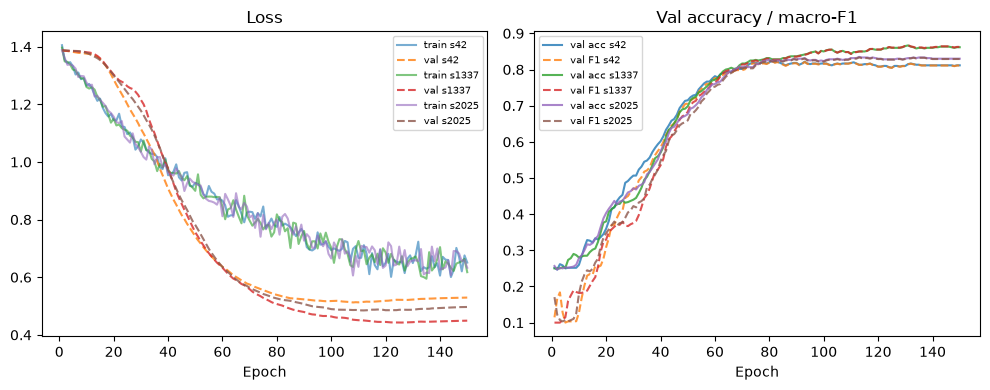

In [6]:
# 6. Train (identical recipe to src/train.py)

def train_one_seed(seed):
    set_seed(seed)
    tr_loader, va_loader, _ = make_loaders(seed=seed)
    model = CNNSE(num_classes=len(CLASS_NAMES), dropout=DROPOUT).to(device)
    optimizer = build_optimizer(model)
    ema = ModelEMA(model)

    steps_per_epoch = len(tr_loader)
    total_steps = steps_per_epoch * EPOCHS
    warmup_steps = steps_per_epoch * WARMUP_EPOCHS
    global_step = 0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_macro_f1": []}
    best_f1, best_epoch, best_state = -1.0, 0, None
    t0 = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in tr_loader:
            images, labels = images.to(device), labels.to(device)
            images, labels, mix = maybe_mix(images, labels)
            lr = lr_at(global_step, total_steps, warmup_steps)
            for g in optimizer.param_groups:
                g["lr"] = lr
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = soft_ce(logits, labels, LABEL_SMOOTHING, mix)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            ema.update(model)
            global_step += 1
            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)

        va_loss, va_acc, va_f1, _, _, _ = evaluate(ema.module, va_loader, device)
        history["train_loss"].append(running_loss / max(total, 1))
        history["train_acc"].append(correct / max(total, 1))
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        history["val_macro_f1"].append(va_f1)
        marker = ""
        if va_f1 > best_f1:
            best_f1, best_epoch = va_f1, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in ema.module.state_dict().items()}
            marker = " *"
        print(
            f"[seed {seed}] epoch {epoch:03d}/{EPOCHS} lr={lr:.2e} "
            f"train_loss={history['train_loss'][-1]:.4f} train_acc={history['train_acc'][-1]:.4f} "
            f"val_loss={va_loss:.4f} val_acc={va_acc:.4f} val_f1={va_f1:.4f} ({time.time() - t0:.0f}s){marker}",
            flush=True,
        )

    assert best_state is not None
    ckpt = {
        "arch": "CNN_se",
        "state_dict": best_state,
        "seed": seed,
        "best_val_macro_f1": best_f1,
        "best_epoch": best_epoch,
        "class_names": CLASS_NAMES,
        "mean": mean,
        "std": std,
        "config": {
            "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "wd": WD,
            "warmup_epochs": WARMUP_EPOCHS, "dropout": DROPOUT,
            "label_smoothing": LABEL_SMOOTHING, "mixup_alpha": MIXUP_ALPHA,
            "cutmix_alpha": CUTMIX_ALPHA, "mix_prob": MIX_PROB, "ema_decay": EMA_DECAY,
        },
    }
    ckpt_path = OUTPUT_DIR / f"best_CNN_se_seed{seed}.pt"
    torch.save(ckpt, ckpt_path)
    print(f"[seed {seed}] saved {ckpt_path} (best val macro-F1={best_f1:.4f} @ epoch {best_epoch})")
    return {"seed": seed, "history": history, "best_val_macro_f1": best_f1, "best_epoch": best_epoch}


def plot_curves(runs, out_path):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for r in runs:
        hist, seed = r["history"], r["seed"]
        epochs = range(1, len(hist["train_loss"]) + 1)
        axes[0].plot(epochs, hist["train_loss"], alpha=0.6, label=f"train s{seed}")
        axes[0].plot(epochs, hist["val_loss"], ls="--", alpha=0.8, label=f"val s{seed}")
        axes[1].plot(epochs, hist["val_acc"], alpha=0.8, label=f"val acc s{seed}")
        axes[1].plot(epochs, hist["val_macro_f1"], ls="--", alpha=0.8, label=f"val F1 s{seed}")
    axes[0].set_title("Loss")
    axes[1].set_title("Val accuracy / macro-F1")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


if TRAIN:
    runs = [train_one_seed(s) for s in SEEDS]
    plot_curves(runs, OUTPUT_DIR / "training_curves.png")
else:
    runs = []
    print("TRAIN=False — using existing checkpoints:")
    for s in SEEDS:
        p = OUTPUT_DIR / f"best_CNN_se_seed{s}.pt"
        print(f"  seed {s}: {p}  exists={p.is_file()}")


## 7. One-shot test evaluation (TTA + 3-seed ensemble)

Validation was used only for checkpoint selection (best EMA val macro-F1). The test set is evaluated once: per seed, mean softmax over {224, hflip, 256-center-crop, hflip}; ensemble = mean over the 3 seeds.


seed 42: val F1=0.8241 | single+TTA test acc=0.7900 f1=0.7901


seed 1337: val F1=0.8673 | single+TTA test acc=0.8467 f1=0.8468


seed 2025: val F1=0.8335 | single+TTA test acc=0.8417 f1=0.8418

ENSEMBLE+TTA  test acc=0.8283  macro_f1=0.8284


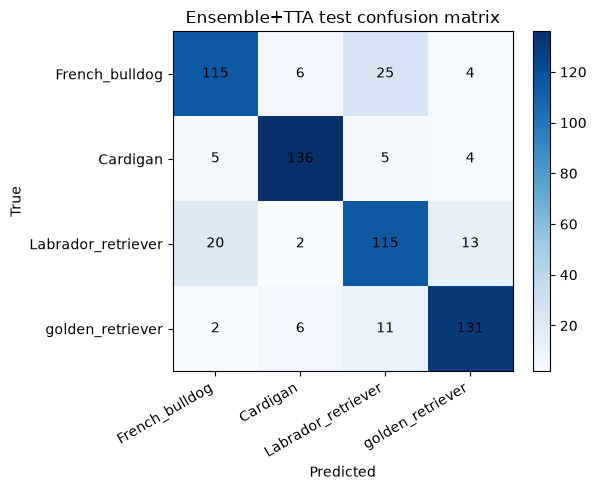

Wrote /Users/rexfufung/Desktop/AI Group project /CNNBuildScratch/outputs/metrics.json


In [7]:
# 7. TTA + ensemble one-shot test

def load_model(ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model = CNNSE(num_classes=len(CLASS_NAMES))
    model.load_state_dict(ckpt["state_dict"])
    return model.to(device).eval(), ckpt


def plot_confusion(cm, out_path, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_yticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


tta_test = make_tta_loader("test")
seed_results, test_probs, test_labels = [], [], None
for seed in SEEDS:
    ckpt_path = OUTPUT_DIR / f"best_CNN_se_seed{seed}.pt"
    if not ckpt_path.is_file():
        raise FileNotFoundError(f"Missing {ckpt_path} — set TRAIN=True and Run All, or restore the checkpoint.")
    model, ckpt = load_model(ckpt_path, device)
    probs, labels = predict_probs(model, test_loader, device, tta_loader=tta_test)
    test_probs.append(probs)
    test_labels = labels
    preds = probs.argmax(1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro", zero_division=0)
    seed_results.append({
        "seed": seed,
        "best_val_macro_f1": ckpt.get("best_val_macro_f1"),
        "best_epoch": ckpt.get("best_epoch"),
        "test_tta_acc": acc,
        "test_tta_macro_f1": f1,
    })
    print(f"seed {seed}: val F1={ckpt.get('best_val_macro_f1'):.4f} | single+TTA test acc={acc:.4f} f1={f1:.4f}")

ens_probs = np.mean(test_probs, axis=0)
ens_preds = ens_probs.argmax(1)
ens_acc = accuracy_score(test_labels, ens_preds)
ens_f1 = f1_score(test_labels, ens_preds, average="macro", zero_division=0)
cm = confusion_matrix(test_labels, ens_preds, labels=list(range(len(CLASS_NAMES))))
print(f"\nENSEMBLE+TTA  test acc={ens_acc:.4f}  macro_f1={ens_f1:.4f}")
plot_confusion(cm, OUTPUT_DIR / "confusion_matrix.png", "Ensemble+TTA test confusion matrix")

metrics = {
    "config": {
        "epochs": EPOCHS, "seeds": SEEDS, "batch_size": BATCH_SIZE, "lr": LR, "wd": WD,
        "warmup_epochs": WARMUP_EPOCHS, "dropout": DROPOUT, "label_smoothing": LABEL_SMOOTHING,
        "mixup_alpha": MIXUP_ALPHA, "cutmix_alpha": CUTMIX_ALPHA, "mix_prob": MIX_PROB,
        "ema_decay": EMA_DECAY, "trained_in_notebook": bool(TRAIN),
    },
    "device": str(device),
    "class_counts": split_meta.get("class_counts"),
    "runs": seed_results,
    "test_ensemble": {
        "accuracy": ens_acc,
        "macro_f1": ens_f1,
        "confusion_matrix": cm.tolist(),
        "class_names": CLASS_NAMES,
        "n_seeds": len(SEEDS),
        "tta": "mean softmax over {224, hflip, 256-center-crop, hflip} x seeds",
    },
}
with (OUTPUT_DIR / "metrics.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print(f"Wrote {OUTPUT_DIR / 'metrics.json'}")


## Summary

With the saved checkpoints (`TRAIN = False`), cell 7 reproduces the reported numbers:

- seed 42 single+TTA: **79.0%** · seed 1337: **84.7%** · seed 2025: **84.2%**
- **3-seed ensemble + TTA: 82.83%** test accuracy (macro-F1 0.828)

Full reproduction from scratch: set `TRAIN = True` in cell 1 → Run All (~4–5 h on MPS). Training logs for the original run: `outputs/logs/full_3seeds_150ep.log`.
